# LeNet-5 trên MNIST

Notebook này thực hiện các phần khám phá dữ liệu, xây dựng mô hình, huấn luyện và đánh giá theo đề bài. Theo yêu cầu, notebook **chỉ dùng MNIST**; không tải hoặc xử lý CIFAR-10.

Mô hình được huấn luyện tối đa 15 epoch (đề bài yêu cầu 10–15). Dropout, L2 regularization, giảm learning rate khi validation loss chững lại và EarlyStopping giúp hạn chế overfit; trọng số tốt nhất theo `val_loss` được khôi phục và lưu thành file `.keras`.

## 1. Import thư viện và cấu hình

In [15]:
import random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

CLASS_NAMES = [str(i) for i in range(10)]
print('TensorFlow:', tf.__version__)

TensorFlow: 2.20.0


## 2. Tải dataset MNIST

MNIST gồm ảnh chữ số viết tay kích thước 28×28, một kênh xám. Tập test được giữ riêng và chỉ dùng ở bước đánh giá cuối.

In [16]:
(x_train_raw, y_train_raw), (x_test_raw, y_test_raw) = tf.keras.datasets.mnist.load_data()
print(f'Số mẫu train gốc: {len(x_train_raw):,}')
print(f'Số mẫu test: {len(x_test_raw):,}')
print('Kích thước một ảnh:', x_train_raw[0].shape)
print('Tên 10 lớp:', CLASS_NAMES)
print('Phân bố label train:', np.bincount(y_train_raw))

Số mẫu train gốc: 60,000
Số mẫu test: 10,000
Kích thước một ảnh: (28, 28)
Tên 10 lớp: ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']
Phân bố label train: [5923 6742 5958 6131 5842 5421 5918 6265 5851 5949]


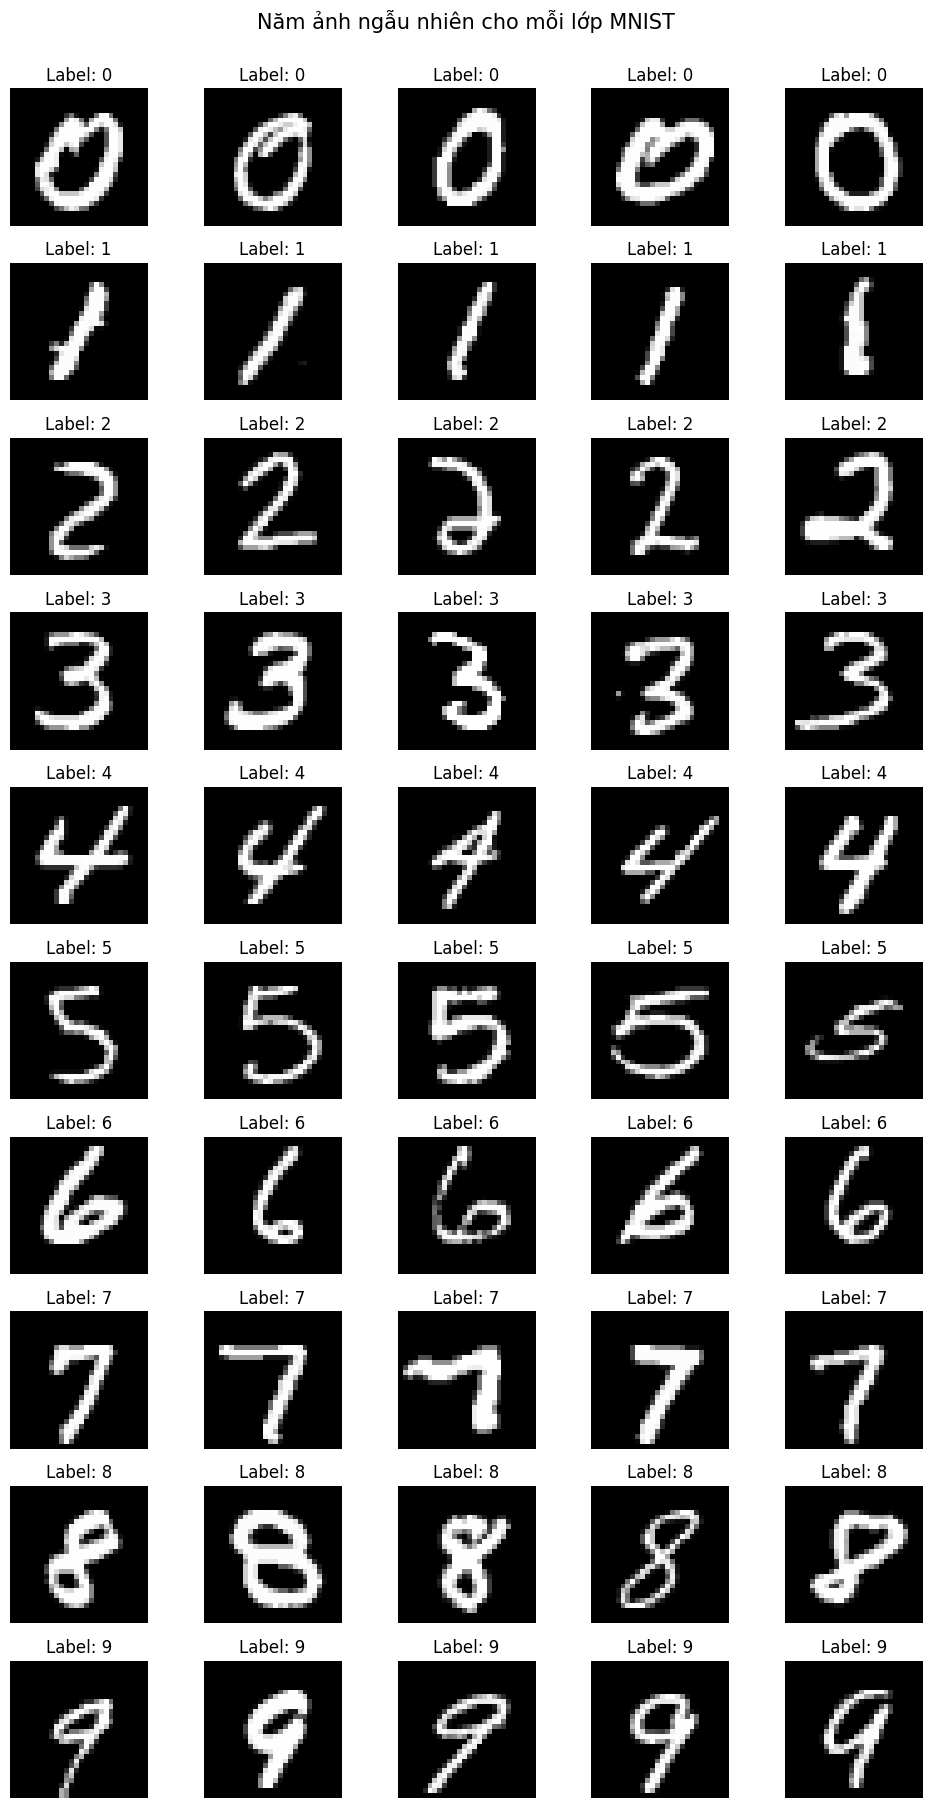

In [17]:
# Mỗi hàng là một lớp; lấy ngẫu nhiên 5 ảnh cho từng chữ số.
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(10, 5, figsize=(10, 18))
for digit in range(10):
    indices = np.flatnonzero(y_train_raw == digit)
    chosen = rng.choice(indices, size=5, replace=False)
    for col, idx in enumerate(chosen):
        axes[digit, col].imshow(x_train_raw[idx], cmap='gray')
        axes[digit, col].set_title(f'Label: {digit}')
        axes[digit, col].axis('off')
fig.suptitle('Năm ảnh ngẫu nhiên cho mỗi lớp MNIST', y=1.002, fontsize=15)
plt.tight_layout()
plt.show()

## 3. Tiền xử lý và chia validation

Giá trị pixel được đổi sang `float32` và chuẩn hóa về [0, 1]. Thêm chiều kênh để phù hợp với `Conv2D`, one-hot encode nhãn, rồi chia train gốc theo tỷ lệ 80/20 có phân tầng theo lớp.

In [18]:
x_all = (x_train_raw.astype('float32') / 255.0)[..., np.newaxis]
x_test = (x_test_raw.astype('float32') / 255.0)[..., np.newaxis]
y_all = tf.keras.utils.to_categorical(y_train_raw, num_classes=10)
y_test = tf.keras.utils.to_categorical(y_test_raw, num_classes=10)

train_idx, val_idx = train_test_split(
    np.arange(len(x_all)), test_size=0.20, random_state=SEED, stratify=y_train_raw
)
x_train, x_val = x_all[train_idx], x_all[val_idx]
y_train, y_val = y_all[train_idx], y_all[val_idx]
print('Train:', x_train.shape, y_train.shape)
print('Validation:', x_val.shape, y_val.shape)
print('Test:', x_test.shape, y_test.shape)
print('Pixel range:', float(x_train.min()), 'to', float(x_train.max()))

Train: (48000, 28, 28, 1) (48000, 10)
Validation: (12000, 28, 28, 1) (12000, 10)
Test: (10000, 28, 28, 1) (10000, 10)
Pixel range: 0.0 to 1.0


## 4. Xây dựng kiến trúc LeNet-5

Hai lớp convolution dùng kernel 5×5 và `tanh`; sau mỗi convolution là average pooling 2×2. Dense layers có lần lượt 120 và 84 units, đầu ra softmax 10 lớp.

In [19]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),
    # Dịch nhẹ ảnh để tăng khả năng khái quát; chỉ hoạt động khi training.
    tf.keras.layers.RandomTranslation(height_factor=0.05, width_factor=0.05),
    tf.keras.layers.Conv2D(6, kernel_size=(5, 5), strides=1, activation='tanh'),
    tf.keras.layers.AveragePooling2D(pool_size=(2, 2), strides=2),
    tf.keras.layers.Conv2D(16, kernel_size=(5, 5), strides=1, activation='tanh'),
    tf.keras.layers.AveragePooling2D(pool_size=(2, 2), strides=2),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(120, activation='tanh', kernel_regularizer=tf.keras.regularizers.l2(1e-4)),
    tf.keras.layers.Dropout(0.20),
    tf.keras.layers.Dense(84, activation='tanh', kernel_regularizer=tf.keras.regularizers.l2(1e-4)),
    tf.keras.layers.Dropout(0.10),
    tf.keras.layers.Dense(10, activation='softmax'),
])
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=[tf.keras.metrics.Precision(name='precision'), tf.keras.metrics.Recall(name='recall'), 'accuracy'],
)
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_translation              │ (None, 28, 28, 1)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 24, 24, 6)      │           156 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_2             │ (None, 12, 12, 6)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 8, 8, 16)       │         2,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_3             │ (None, 4, 4, 16)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 120)            │        30,840 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 120)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 84)             │        10,164 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 84)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │           850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 44,426 (173.54 KB)

 Trainable params: 44,426 (173.54 KB)

 Non-trainable params: 0 (0.00 B)

## 5. Huấn luyện tối đa 15 epoch

Keras in Loss, Precision và Recall trên cả train và validation sau mỗi epoch. `batch_size=128` giúp huấn luyện ổn định trên CPU thông thường.

In [20]:
callbacks = [
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=2, min_lr=1e-5, verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=4, start_from_epoch=9,
        restore_best_weights=True, verbose=1
    ),
]

history = model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=15,
    batch_size=128,
    callbacks=callbacks,
    verbose=1,
)

Epoch 1/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.8173 - loss: 0.6380 - precision: 0.8900 - recall: 0.7403 - val_accuracy: 0.9317 - val_loss: 0.2560 - val_precision: 0.9483 - val_recall: 0.9183 - learning_rate: 0.0010
Epoch 2/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9182 - loss: 0.3011 - precision: 0.9368 - recall: 0.9021 - val_accuracy: 0.9592 - val_loss: 0.1640 - val_precision: 0.9674 - val_recall: 0.9515 - learning_rate: 0.0010
Epoch 3/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9460 - loss: 0.2110 - precision: 0.9570 - recall: 0.9378 - val_accuracy: 0.9677 - val_loss: 0.1403 - val_precision: 0.9723 - val_recall: 0.9629 - learning_rate: 0.0010
Epoch 4/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9581 - loss: 0.1712 - precision: 0.9656 - recall: 0.9519 - val_accuracy: 0.9732 - val_loss: 0.1213 - val_precision: 0.9765 - val_recall: 0.9697 - learning_rate: 0.0010
Epoch 5/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 

## 6. Lưu model đã huấn luyện

EarlyStopping khôi phục trọng số có `val_loss` tốt nhất. Cell dưới lưu kiến trúc và trọng số ở định dạng Keras `.keras`; trên Kaggle lưu vào `/kaggle/working`

In [ ]:
from pathlib import Path

# Kaggle giữ file trong /kaggle/working để tải từ tab Output.
if Path('/kaggle/working').is_dir():
    output_dir = Path('/kaggle/working')
elif (Path.cwd() / 'PCT' / 'cnn').is_dir():
    output_dir = Path.cwd() / 'PCT' / 'cnn'
elif Path.cwd().name == 'cnn':
    output_dir = Path.cwd()
else:
    output_dir = Path.cwd()

output_dir.mkdir(parents=True, exist_ok=True)
model_path = output_dir / 'lenet5_mnist.keras'
model.save(model_path)
print(f'Model đã lưu tại: {model_path.resolve()}')

Model tốt nhất đã lưu tại: /kaggle/working/lenet5_mnist.keras


## 7. Biểu đồ Loss, Precision và Recall

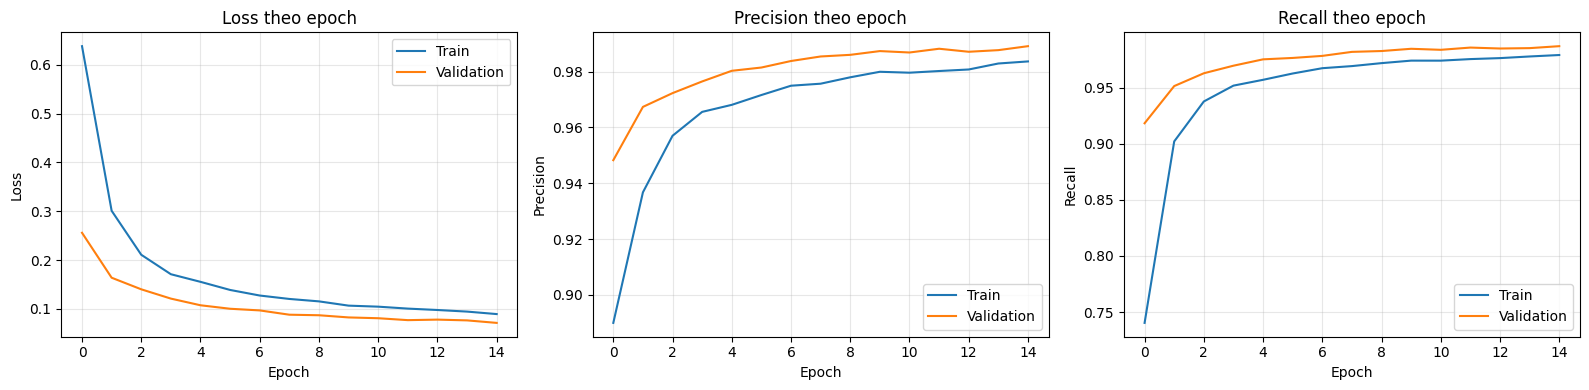

In [22]:
metrics_to_plot = [
    ('loss', 'Loss'),
    ('precision', 'Precision'),
    ('recall', 'Recall'),
]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (key, title) in zip(axes, metrics_to_plot):
    ax.plot(history.history[key], label='Train')
    ax.plot(history.history[f'val_{key}'], label='Validation')
    ax.set_title(f'{title} theo epoch')
    ax.set_xlabel('Epoch')
    ax.set_ylabel(title)
    ax.grid(True, alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

## 8. Đánh giá trên tập test

Chỉ sau khi huấn luyện hoàn tất, đánh giá mô hình trên 10.000 ảnh test chưa dùng để tối ưu mô hình.

In [23]:
test_results = model.evaluate(x_test, y_test, verbose=0, return_dict=True)
print('Kết quả trên test:')
for metric, value in test_results.items():
    print(f'{metric}: {value:.4f}')

y_pred_prob = model.predict(x_test, batch_size=256, verbose=1)
y_pred = np.argmax(y_pred_prob, axis=1)
y_true = y_test_raw
print('\nClassification report:')
print(classification_report(y_true, y_pred, labels=range(10), target_names=CLASS_NAMES, digits=4))

Kết quả trên test:
accuracy: 0.9899
loss: 0.0612
precision: 0.9907
recall: 0.9890
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step

Classification report:
              precision    recall  f1-score   support

           0     0.9959    0.9918    0.9939       980
           1     0.9947    0.9956    0.9952      1135
           2     0.9913    0.9893    0.9903      1032
           3     0.9833    0.9911    0.9872      1010
           4     0.9878    0.9898    0.9888       982
           5     0.9877    0.9933    0.9905       892
           6     0.9906    0.9906    0.9906       958
           7     0.9912    0.9864    0.9888      1028
           8     0.9877    0.9908    0.9892       974
           9     0.9880    0.9802    0.9841      1009

    accuracy                         0.9899     10000
   macro avg     0.9898    0.9899    0.9899     10000
weighted avg     0.9899    0.9899    0.9899     10000



## 9. Confusion Matrix

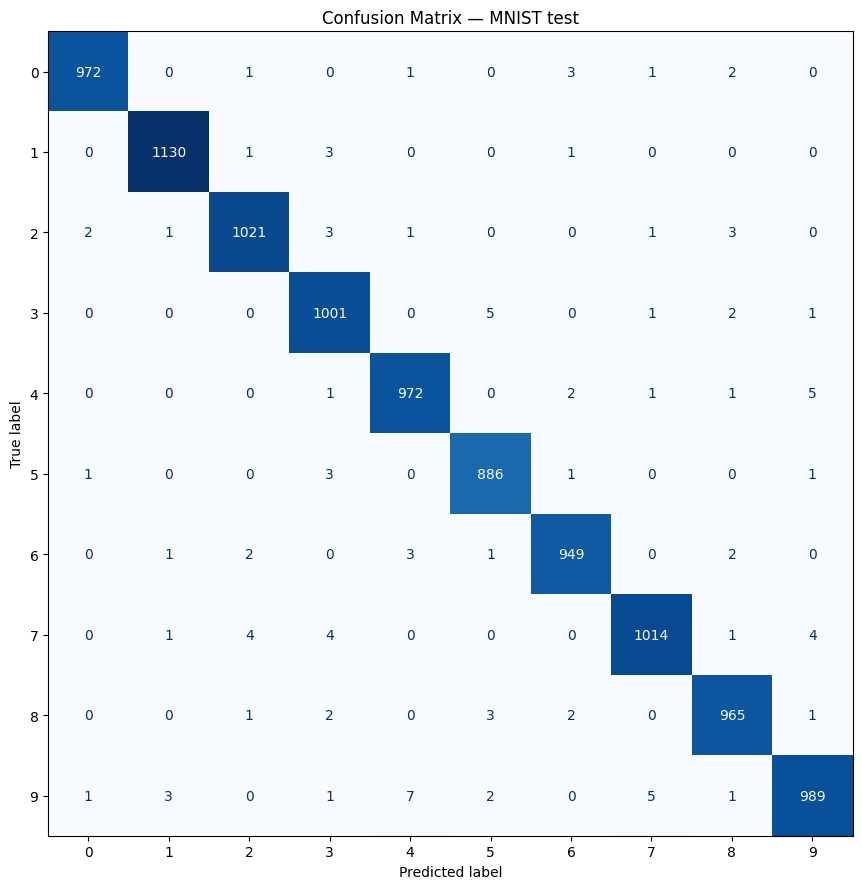

In [24]:
cm = confusion_matrix(y_true, y_pred, labels=range(10))
display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASS_NAMES)
fig, ax = plt.subplots(figsize=(9, 9))
display.plot(ax=ax, cmap='Blues', values_format='d', colorbar=False)
ax.set_title('Confusion Matrix — MNIST test')
plt.tight_layout()
plt.show()

## 10. Ví dụ dự đoán đúng và sai

Hiển thị 5 ví dụ đúng và 5 ví dụ sai (nếu có), kèm nhãn dự đoán và nhãn thật.

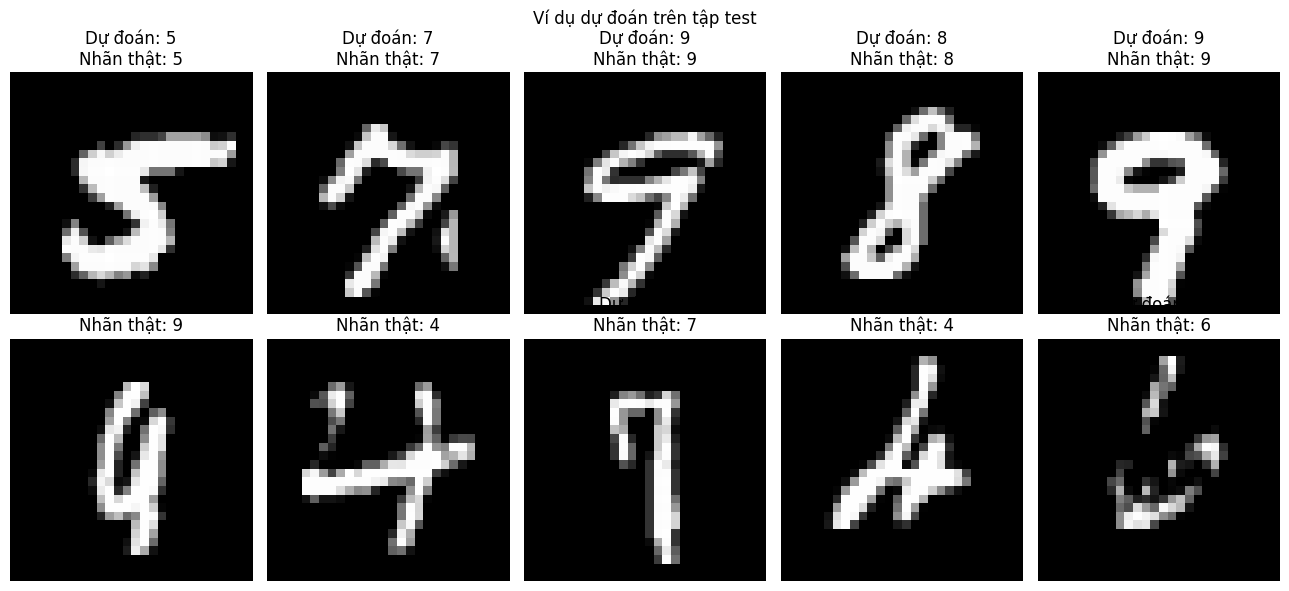

Số mẫu dự đoán đúng: 9,899
Số mẫu dự đoán sai: 101


In [25]:
correct_idx = np.flatnonzero(y_pred == y_true)
incorrect_idx = np.flatnonzero(y_pred != y_true)
correct_show = rng.choice(correct_idx, size=min(5, len(correct_idx)), replace=False)
incorrect_show = rng.choice(incorrect_idx, size=min(5, len(incorrect_idx)), replace=False)

fig, axes = plt.subplots(2, 5, figsize=(13, 6))
for row, indices, heading in [(0, correct_show, 'Dự đoán đúng'), (1, incorrect_show, 'Dự đoán sai')]:
    for col in range(5):
        ax = axes[row, col]
        if col < len(indices):
            idx = indices[col]
            ax.imshow(x_test_raw[idx], cmap='gray')
            ax.set_title(f'Dự đoán: {y_pred[idx]}\nNhãn thật: {y_true[idx]}')
        else:
            ax.text(0.5, 0.5, 'Không có ví dụ', ha='center', va='center')
        ax.axis('off')
    axes[row, 0].set_ylabel(heading, fontsize=11)
fig.suptitle('Ví dụ dự đoán trên tập test')
plt.tight_layout()
plt.show()
print(f'Số mẫu dự đoán đúng: {len(correct_idx):,}')
print(f'Số mẫu dự đoán sai: {len(incorrect_idx):,}')